In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_parquet("../data/processed/df_clean.parquet")

c:\Users\Simrat Khalsa\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
product_counts = (
    df.groupby("product_id")
    .size()
    .sort_values(ascending=False)
)

display(product_counts.head(20))

product_id
P420652    16084
P7880       8730
P218700     7761
P248407     7545
P269122     7327
P394639     7279
P450271     6141
P417238     6141
P427421     6045
P411387     5852
P441644     5842
P427417     5775
P309308     5396
P411540     5315
P42204      5198
P471546     5029
P248404     4728
P443352     4599
P423688     4599
P421275     4576
dtype: int64

In [3]:
product_summary = (
    df.groupby("product_id")
    .agg(
        total_reviews=("rating", "size"),
        average_rating=("rating", "mean"),
        negative_reviews=("rating_group", lambda x: (x == "Negative").sum()),
        mixed_reviews=("rating_group", lambda x: (x == "Neutral/Mixed").sum()),
        positive_reviews=("rating_group", lambda x: (x == "Positive").sum())
    )
)

product_summary["negative_pct"] = (
    product_summary["negative_reviews"] /
    product_summary["total_reviews"] * 100
)

product_summary["mixed_pct"] = (
    product_summary["mixed_reviews"] /
    product_summary["total_reviews"] * 100
)

display(
    product_summary
    .query("total_reviews >= 500")
    .sort_values("mixed_reviews", ascending=False)
    .head(20)
)

,total_reviews,average_rating,negative_reviews,mixed_reviews,positive_reviews,negative_pct,mixed_pct
product_id,,,,,,,
P420652,16084,4.349105,1857,1065,13162,11.545635,6.621487
P427421,6045,3.960794,1199,602,4244,19.834574,9.958644
P7880,8730,4.362658,839,596,7295,9.610538,6.827033
P411540,5315,3.989464,934,581,3800,17.572907,10.931326
P411387,5852,4.210526,775,550,4527,13.243336,9.398496
P441644,5842,4.211400,773,548,4521,13.231770,9.380349
P471546,5029,4.015709,846,544,3639,16.822430,10.817260
P418218,4159,4.023323,745,435,2979,17.912960,10.459245
P454794,4159,4.023323,745,435,2979,17.912960,10.459245


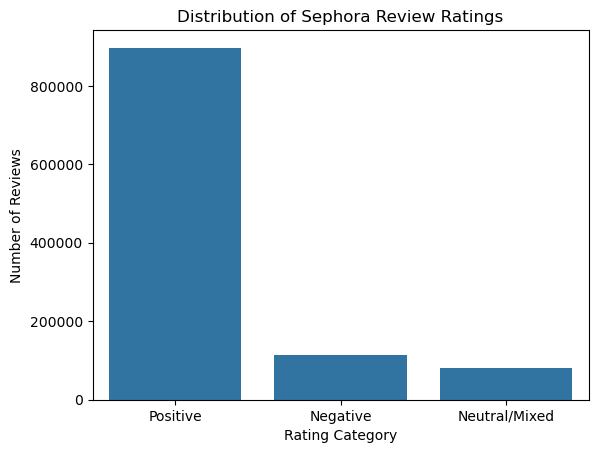

In [4]:
rating_counts = df["rating_group"].value_counts()

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Distribution of Sephora Review Ratings")
plt.xlabel("Rating Category")
plt.ylabel("Number of Reviews")
plt.show()

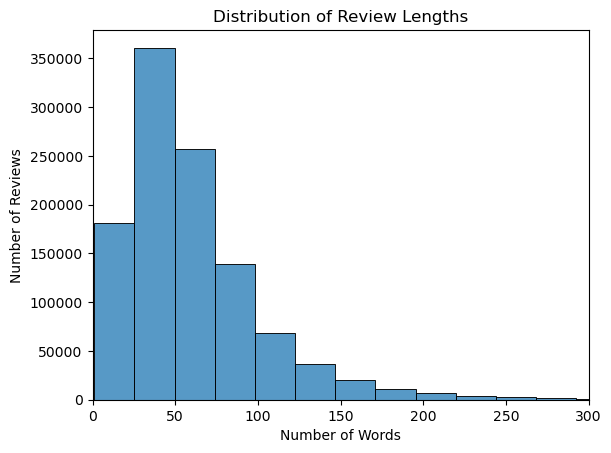

In [5]:
sns.histplot(
    df["review_length_words"],
    bins=50
)

plt.xlim(0, 300)
plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.show()

In [6]:
top_ids = product_counts.head(20).index

top_product_summary = (
    product_summary
    .loc[top_ids]
    .sort_values("mixed_pct", ascending=False)
)

display(
    top_product_summary[
        [
            "total_reviews",
            "average_rating",
            "negative_pct",
            "mixed_pct"
        ]
    ].round(2)
)

,total_reviews,average_rating,negative_pct,mixed_pct
product_id,,,,
P411540,5315,3.99,17.57,10.93
P471546,5029,4.02,16.82,10.82
P427421,6045,3.96,19.83,9.96
P411387,5852,4.21,13.24,9.40
P441644,5842,4.21,13.23,9.38
P7880,8730,4.36,9.61,6.83
P420652,16084,4.35,11.55,6.62
P421275,4576,4.18,14.55,6.36
P248404,4728,4.37,9.79,6.20


In [7]:
print(df.columns.tolist())

['Unnamed: 0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id', 'product_name', 'brand_name', 'price_usd', 'primary_category', 'secondary_category', 'tertiary_category', 'size', 'loves_count', 'review_length_words', 'review_length_chars', 'rating_group']


# Two-Case-Study analysis

### Dior
Existing demo, used to demonstrate how the multi-agent system works

### Mixed-review product 
A more challenging case, to investigate whether Nuance can identify conflicting customer experiences and actionable marketing problems.

In [8]:
# Retrieve three mixed-review candidates
candidate_ids = ["P427421", "P411540", "P471546"]

candidate_products = (
    df.loc[
        df["product_id"].isin(candidate_ids),
        [
            "product_id",
            "product_name",
            "brand_name"
        ]
    ]
    .drop_duplicates()
)

display(candidate_products)

,product_id,product_name,brand_name
67009,P427421,Protini Polypeptide Firming Refillable Moistur...,Drunk Elephant
95919,P411540,Cicapair Tiger Grass Color Correcting Treatmen...,Dr. Jart+
106432,P471546,Mini Cicapair Tiger Grass Color Correcting Tre...,Dr. Jart+


In [9]:
# Understanding Dior products
dior_products = (
    df.loc[
        df["brand_name"].str.contains("Dior", case=False, na=False)
    ]
    .groupby(["product_id", "product_name", "brand_name"])
    .agg(
        total_reviews=("rating", "size"),
        average_rating=("rating", "mean"),
        negative_reviews=("rating_group", lambda x: (x == "Negative").sum()),
        mixed_reviews=("rating_group", lambda x: (x == "Neutral/Mixed").sum())
    )
    .reset_index()
)

display(dior_products.sort_values("total_reviews", ascending=False))

,product_id,product_name,brand_name,total_reviews,average_rating,negative_reviews,mixed_reviews
2,P415619,Dreamskin Skin Perfector,Dior,1457,4.338367,81,138
18,P472028,Capture Totale Super Potent Eye Serum,Dior,1092,4.383700,36,106
17,P467945,Capture Totale Super Potent Rich Cream,Dior,678,4.545723,15,51
15,P454806,Capture Totale Firming & Wrinkle-Correcting Cream,Dior,654,4.516820,15,49
20,P480162,Cica Recover & Repair Multi-Use Balm,Dior,611,4.641571,4,33
25,P481972,La Mousse OFF/ON Foaming Face Cleanser,Dior,561,4.422460,18,48
26,P503999,Capture Totale Le Sérum Anti-Aging Serum,Dior,500,4.446000,10,46
9,P428255,Capture Youth Serum Collection,Dior,151,4.238411,21,11
6,P427729,Capture Youth Age-Delay Advanced Crème,Dior,64,3.921875,11,10
5,P423264,One Essential Skin Boosting Super Serum,Dior,54,4.388889,6,3


In [10]:
candidate_reviews = df.loc[
    (df["product_id"] == "P427421") &
    (df["rating_group"].isin(["Negative", "Neutral/Mixed"]))
]

display(
    candidate_reviews[
        ["rating", "review_title", "review_text"]
    ].sample(n=min(15, len(candidate_reviews)), random_state=42)
)

,rating,review_title,review_text
69986,2,NaN,the smell is so bad. too heavy but not very hy...
72590,2,NaN,This one has a nice feel to it and I like the ...
69410,2,Meh.,As someone with dry skin and issues with fine ...
67570,3,Good but too expensive,"This is a great, lightweight, moisturizer. It ..."
70863,1,Disappointing performance,The product is a nice light moisturizer. I no...
67195,3,Don’t like this product,"When I used this product, it dried my skin aft..."
67990,2,NaN,I’m going to give this one a ‘meh’. Not worth ...
68207,3,Meh,I wasn’t wow-ed by this. I was attracted by th...
71783,3,Don’t waste your time.,Didn’t really do much. I felt like if i sweat ...
70068,1,NaN,This product made me break out. I went back to...


In [11]:
# Select the product ids
dior_ids = ["P472028", "P467945", "P454806", "P480162"]
mixed_id = "P427421"

selected_ids = dior_ids + [mixed_id]

df_cases = df.loc[df["product_id"].isin(selected_ids)].copy()

df_cases["case_study"] = df_cases["product_id"].apply(
    lambda x: "Dior" if x in dior_ids else "Drunk Elephant"
)

display(
    df_cases.groupby(
        ["case_study", "product_name", "rating_group"]
    )
    .size()
    .unstack(fill_value=0)
)

rating_group                                                       Negative  \
case_study     product_name                                                   
Dior           Capture Totale Firming & Wrinkle-Correcting Cream         15   
               Capture Totale Super Potent Eye Serum                     36   
               Capture Totale Super Potent Rich Cream                    15   
               Cica Recover & Repair Multi-Use Balm                       4   
Drunk Elephant Protini Polypeptide Firming Refillable Moisturizer      1199   

rating_group                                                       Neutral/Mixed  \
case_study     product_name                                                        
Dior           Capture Totale Firming & Wrinkle-Correcting Cream              49   
               Capture Totale Super Potent Eye Serum                         106   
               Capture Totale Super Potent Rich Cream                         51   
               Cica Recover & Repair Multi-Use Balm                           33   
Drunk Elephant Protini Polypeptide Firming Refillable Moisturizer            602   

rating_group                                                       Positive  
case_study     product_name                                                  
Dior           Capture Totale Firming & Wrinkle-Correcting Cream        590  
               Capture Totale Super Potent Eye Serum                    950  
               Capture Totale Super Potent Rich Cream                   612  
               Cica Recover & Repair Multi-Use Balm                     574  
Drunk Elephant Protini Polypeptide Firming Refillable Moisturizer      4244

In [ ]:
# Add dataset to the data folder
df_cases.to_parquet(
    "../data/processed/case_study_reviews.parquet",
    index=False
)